In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('train.csv')

In [3]:
df.head()

,PRODUCT_ID,TITLE,BULLET_POINTS,DESCRIPTION,PRODUCT_TYPE_ID,PRODUCT_LENGTH
0,1500446,"DV8 Bowling Tactic Control Ball, Red/Light Blu...",[The Tactic Control is DV8's first urethane ba...,Get your game under control with DV8's Tactic ...,3306,1299.999999
1,2833637,LOOM TREE 20x30cm Vintage Metal Tin Sign Plaqu...,"[Waterproof, Non-glare, Clean simple and Color...",<p> <strong>Description:</strong></p><ul> <li>...,1557,314.960630
2,835287,Triton Products B1 XtraWall Wall Mount Double-...,NaN,NaN,0,175.000000
3,2095634,"ASICS Men's Jolt 3, Black/Graphite Grey, 12 X-...","[Flexible mesh upper -,Synthetic stitching on ...",The new JOLT 3 (Extra Wide) shoe is designed t...,3224,1000.000000
4,718866,The Artist's House: From Workplace to Artwork,NaN,NaN,15,694.000000


In [4]:
# eliminate product_id first

In [5]:
df.drop(columns = ['PRODUCT_ID'],inplace = True)

In [6]:
df.head()

,TITLE,BULLET_POINTS,DESCRIPTION,PRODUCT_TYPE_ID,PRODUCT_LENGTH
0,"DV8 Bowling Tactic Control Ball, Red/Light Blu...",[The Tactic Control is DV8's first urethane ba...,Get your game under control with DV8's Tactic ...,3306,1299.999999
1,LOOM TREE 20x30cm Vintage Metal Tin Sign Plaqu...,"[Waterproof, Non-glare, Clean simple and Color...",<p> <strong>Description:</strong></p><ul> <li>...,1557,314.960630
2,Triton Products B1 XtraWall Wall Mount Double-...,NaN,NaN,0,175.000000
3,"ASICS Men's Jolt 3, Black/Graphite Grey, 12 X-...","[Flexible mesh upper -,Synthetic stitching on ...",The new JOLT 3 (Extra Wide) shoe is designed t...,3224,1000.000000
4,The Artist's House: From Workplace to Artwork,NaN,NaN,15,694.000000


In [7]:
df.shape

(400000, 5)

In [8]:
df.sample(10)

,TITLE,BULLET_POINTS,DESCRIPTION,PRODUCT_TYPE_ID,PRODUCT_LENGTH
122146,Jaipur Kurti Women's Cotton Pleated Kurta (Jk4...,"[Color Name: Blue,Material: Cotton with three ...",NaN,2916,1181.100000
394834,American Weigh Scales Blue Blade Series BL2-50...,NaN,NaN,1311,675.000000
326670,Caroline's Treasures SS8370SH4 Starry Night Da...,[The tile is made from a hardboard and is moun...,Starry Night Dalmatian Leash Holder or Key Hoo...,1703,400.000000
310577,Mittelassyrische Urkunden Aus Dem Archiv Assur...,NaN,NaN,6324,945.000000
254271,Rostyle Luxury Fluffy Area Rugs Shag Indoor Nu...,[✔【SUPER SOFT FLUFFY RUG】Rostyle soft rug is m...,<b>Rostyle shaggy area rug kid's rug for nurse...,1636,10800.000000
9081,Walking Pair Bunny Slip On Pink Fur Slippers F...,[Apair of flip flops with the Fur design and e...,Elevate your style with this comfortable pair ...,3195,984.251967
263926,"Sugoiti Balloons Garland Arch 99PCS Kit 40"" Fl...",[Memorable Party Backdrop: You will get a very...,NaN,1106,900.000000
25262,Wappen LOGO Index 2010,NaN,NaN,1,744.093000
260851,Psychiatry the State of the Art: Volume 6 Drug...,NaN,NaN,6243,614.172000
158438,What Keeps Her Awake at Night?: Women's Uncomf...,NaN,NaN,87,500.000000


In [9]:
df.isna().sum()

TITLE                   0
BULLET_POINTS       75792
DESCRIPTION        148563
PRODUCT_TYPE_ID         0
PRODUCT_LENGTH          0
dtype: int64

In [10]:
# let's focus on removing null values first. but how?
#dropping ain't a choice... that would be dropping a lot of data...
# let's try plotting to capture more relationships...

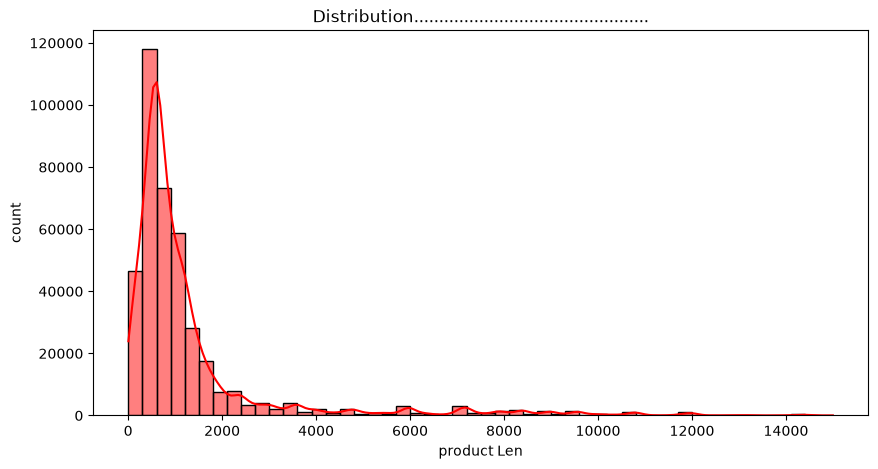

In [11]:
plt.figure(figsize=(10, 5))
sns.histplot(df['PRODUCT_LENGTH'], bins=50, kde=True, color='red')
plt.title('Distribution...............................................')
plt.xlabel('product Len')
plt.ylabel('count')
plt.show()

In [12]:
# mmhmhmhmhmhmhmhmhmhm..... most of the objects are <=1000mm...
#doesn't solve anything yet.

In [13]:
#ahaaaa product_type_id is categorical seems.or no? let's check. guess it rendered one twice in the head... idk...
df['PRODUCT_TYPE_ID'].nunique()

9429

In [14]:
#mhm... 9429 'unique' rows for 400000 entities... mhmmmm....
# and Regression it is. fuck.
#can we try to fill an empty string in those NaN values?? it may work. but it is still almost 1/3th of the data set...

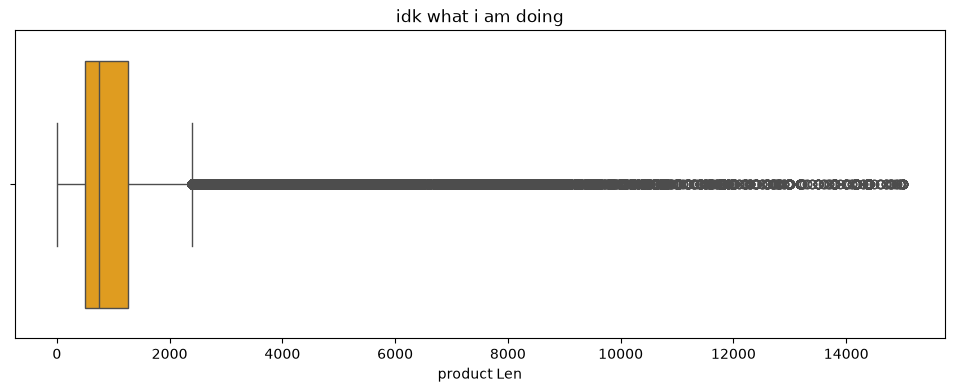

In [15]:
plt.figure(figsize=(12, 4))
sns.boxplot(x=df['PRODUCT_LENGTH'], color='orange')
plt.title('idk what i am doing')
plt.xlabel('product Len')
plt.show()

C:\Users\Nisha\AppData\Local\Temp\ipykernel_24780\3530874666.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='PRODUCT_TYPE_ID', y='PRODUCT_LENGTH', data=df[df['PRODUCT_TYPE_ID'].isin(top)], palette='Set2')


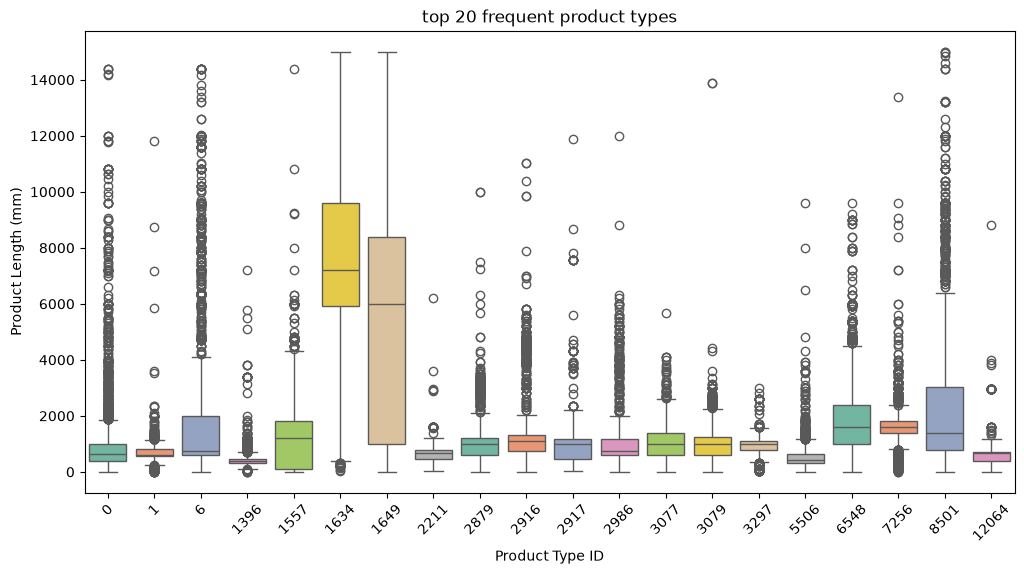

In [16]:
plt.figure(figsize=(12, 6))
top = df['PRODUCT_TYPE_ID'].value_counts().head(20).index
sns.boxplot(x='PRODUCT_TYPE_ID', y='PRODUCT_LENGTH', data=df[df['PRODUCT_TYPE_ID'].isin(top)], palette='Set2')
plt.title('top 20 frequent product types')
plt.xlabel('Product Type ID')
plt.ylabel('Product Length (mm)')
plt.xticks(rotation=45)
plt.show()

In [17]:
df['BULLET_POINTS'] = df['BULLET_POINTS'].fillna('')
df['DESCRIPTION'] = df['DESCRIPTION'].fillna('')

In [18]:
df.sample(5)

,TITLE,BULLET_POINTS,DESCRIPTION,PRODUCT_TYPE_ID,PRODUCT_LENGTH
122144,ArtzFolio Wild African Male Lion Paper Poster ...,[ELEGANT & AFFORDABLE: Magnificent piece of ar...,,1557,1614.170
262050,Goodyear Shatterproof Window Deflectors for Ch...,[Attention! Vent Deflector FITS ONLY for Chevr...,GOODYEAR SIDE WINDOW DEFLECTORS the famous hig...,7347,4626.000
306444,SOA Lecture Series (Applied Physics) Newton's ...,,,1,799.211
368277,"Tree-Free Greetings Refrigerator Magnet, 3.5x3...","[Extra-strong 3.5-inch magnet,Printed on 100 p...",,1426,350.000
33378,"3dRose fl_16537_1 Tap Chick Garden Flag, 12 by...",[Overall dimension (in inches): 12 x 18; image...,,5569,1200.000


In [19]:
# ok.... the boxplots are overwhelming me... 
X = df.drop(columns=['PRODUCT_LENGTH'])
Y = df['PRODUCT_LENGTH']
lower_bound = np.percentile(Y, 1)
upper_bound = np.percentile(Y, 99)
Y_clipped = np.clip(Y, lower_bound, upper_bound)

In [20]:
Y_clipped.shape

(400000,)

In [21]:
X.shape

(400000, 4)

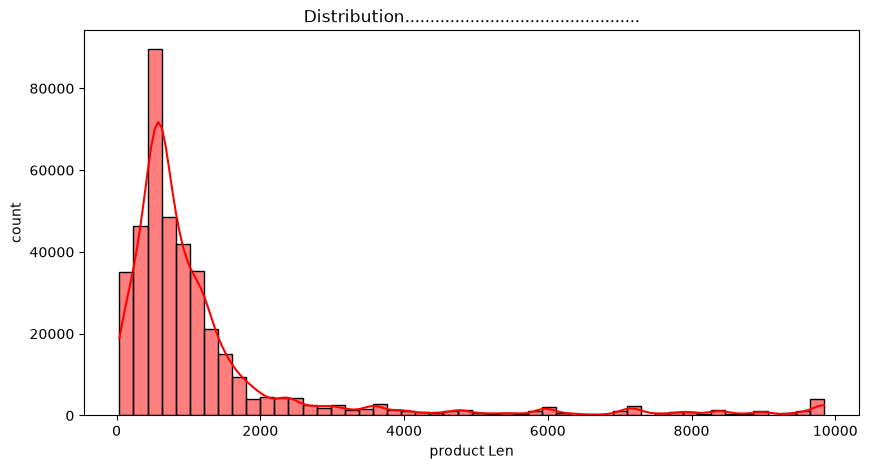

In [22]:
plt.figure(figsize=(10, 5))
sns.histplot(Y_clipped, bins=50, kde=True, color='red')
plt.title('Distribution...............................................')
plt.xlabel('product Len')
plt.ylabel('count')
plt.show()

In [23]:
#meh....aghhhh

In [24]:
import re
def extract_length_from_text(text):
    if not isinstance(text, str):
        return None
    match = re.search(r'(\d+(?:\.\d+)?)\s*(mm|cm|m|inch|inches|"|\'\'|ft)', text, re.IGNORECASE)
    
    if match:
        val = float(match.group(1))
        unit = match.group(2).lower()
        if unit in ['cm']:
            return val * 10
        elif unit in ['m']:
            return val * 1000
        elif unit in ['inch', 'inches', '"', '\'\'']:
            return val * 25.4
        elif unit in ['mm']:
            return val
            
    return None
X = X.copy()
X['extracted_length'] = X['TITLE'].apply(extract_length_from_text)
print("Non-null extracted lengths found:", X['extracted_length'].notnull().sum())
print(X[['TITLE', 'extracted_length']].dropna().head(10))

Non-null extracted lengths found: 103404
                                                TITLE  extracted_length
1   LOOM TREE 20x30cm Vintage Metal Tin Sign Plaqu...             300.0
6   Blue / Multi , 2'3 x 5' : Safavieh Rag Rug Col...              76.2
14  The Pillow Collection Zeljko Geometric Pillow,...             508.0
15  Spanish Frequency Dictionary - Intermediate Vo...         5000000.0
33  FitFlop Women's Uberknit Mary Jane Ballerina F...            5000.0
34  The Oliver Gal Artist Co. Typography Wall Art ...            1371.6
38  Fabric Shower Curtain, Rose Gold Pink Geometry...            1828.8
42  YARWO Double Layer Essential Oil Organizer, Po...            5000.0
50  Mission Belt Men's Ratchet Belt - 35mm Alloy B...              35.0
51  EACHE Quick Release Premium Leather Watch Band...              18.0


In [25]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
import lightgbm as lgb

X_model = X[['PRODUCT_TYPE_ID']].copy()
X_model['extracted_length'] = X['extracted_length'].fillna(0)
X_train_split, X_val_split, y_train_split, y_val_split = train_test_split(
    X_model, Y_clipped, test_size=0.2, random_state=42)

model = lgb.LGBMRegressor(n_estimators=100, random_state=42)
model.fit(X_train_split, y_train_split)
preds = model.predict(X_val_split)
score = r2_score(y_val_split, preds)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003171 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 510
[LightGBM] [Info] Number of data points in the train set: 320000, number of used features: 2
[LightGBM] [Info] Start training from score 1316.183335


In [26]:
score

0.44375503357759083

In [27]:
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import hstack
vectorizer = TfidfVectorizer(max_features=2000, stop_words='english')
X_title_tfidf = vectorizer.fit_transform(X['TITLE'].fillna(''))

print("TF-IDF shape:", X_title_tfidf.shape)

TF-IDF shape: (400000, 2000)


In [28]:
import scipy.sparse as sp
X_numeric = X[['PRODUCT_TYPE_ID']].copy()
X_numeric['extracted_length'] = X['extracted_length'].fillna(0)
X_combined = sp.hstack([X_numeric.values, X_title_tfidf])
X_train_split, X_val_split, y_train_split, y_val_split = train_test_split(
    X_combined, Y_clipped, test_size=0.2, random_state=42
)
model_improved = lgb.LGBMRegressor(n_estimators=150, learning_rate=0.05, random_state=42)
model_improved.fit(X_train_split, y_train_split)
improved_preds = model_improved.predict(X_val_split)
new_score = r2_score(y_val_split, improved_preds)
print(new_score)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 1.085860 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 319250
[LightGBM] [Info] Number of data points in the train set: 320000, number of used features: 2002
[LightGBM] [Info] Start training from score 1316.183335
0.5494479966612144


In [29]:
import catboost as cb
X_cb = X[['PRODUCT_TYPE_ID', 'extracted_length']].copy()
X_cb['extracted_length'] = X_cb['extracted_length'].fillna(0)
X_cb['PRODUCT_TYPE_ID'] = X_cb['PRODUCT_TYPE_ID'].astype('category')

X_train_cb, X_val_cb, y_train_cb, y_val_cb = train_test_split(
    X_cb, Y_clipped, test_size=0.2, random_state=42
)

cb_model = cb.CatBoostRegressor(
    iterations=300, 
    learning_rate=0.1, 
    depth=6, 
    cat_features=['PRODUCT_TYPE_ID'], 
    verbose=50, 
    random_state=42
)

cb_model.fit(X_train_cb, y_train_cb)
cb_preds = cb_model.predict(X_val_cb)
cb_score = r2_score(y_val_cb, cb_preds)

print(cb_score)

0:	learn: 1718.3937851	total: 405ms	remaining: 2m 1s
50:	learn: 1346.2726974	total: 7.7s	remaining: 37.6s
100:	learn: 1329.3610043	total: 16.9s	remaining: 33.3s
150:	learn: 1320.5033938	total: 24.1s	remaining: 23.8s
200:	learn: 1313.9363198	total: 32.2s	remaining: 15.9s
250:	learn: 1309.1824055	total: 41.6s	remaining: 8.13s
299:	learn: 1304.7376525	total: 50.3s	remaining: 0us
0.4583963640055382


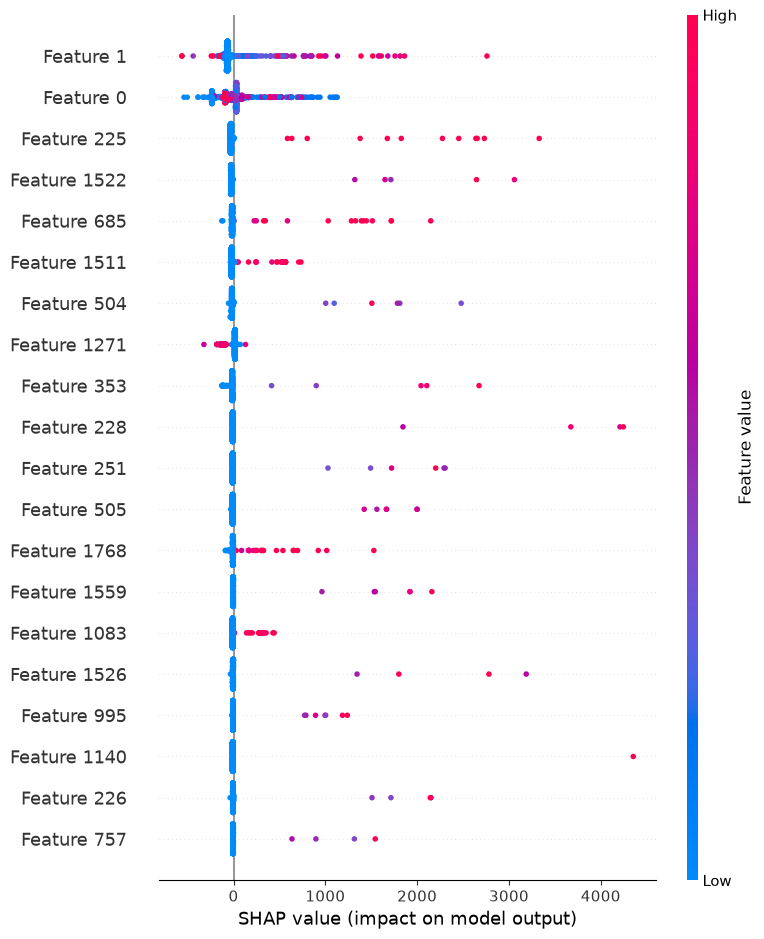

In [30]:
import shap
explainer = shap.TreeExplainer(model_improved)

sample_data = X_val_split[:1000].toarray()
shap_values = explainer(sample_data)
shap.summary_plot(shap_values, sample_data, show=True)

In [31]:
X_text_combined = X['TITLE'].fillna('') + ' ' + X['BULLET_POINTS'].fillna('')
from sklearn.feature_extraction.text import TfidfVectorizer
import scipy.sparse as sp

vectorizer_rich = TfidfVectorizer(max_features=4000, stop_words='english')
X_tfidf_rich = vectorizer_rich.fit_transform(X_text_combined)
X_numeric = X[['PRODUCT_TYPE_ID']].copy()
X_numeric['extracted_length'] = X['extracted_length'].fillna(0)

X_all_combined = sp.hstack([X_numeric.values, X_tfidf_rich])
X_train_split, X_val_split, y_train_split, y_val_split = train_test_split(
    X_all_combined, Y_clipped, test_size=0.2, random_state=42)

model_v3 = lgb.LGBMRegressor(n_estimators=200, learning_rate=0.05, random_state=42)
model_v3.fit(X_train_split, y_train_split)
preds_v3 = model_v3.predict(X_val_split)
score_v3 = r2_score(y_val_split, preds_v3)

print(score_v3)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 4.677605 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 832912
[LightGBM] [Info] Number of data points in the train set: 320000, number of used features: 4002
[LightGBM] [Info] Start training from score 1316.183335
0.5898473562646165


In [32]:
import scipy.sparse as sp
def extract_dimensions(text):
    if not isinstance(text, str):
        return 0.0, 0.0
    length_match = re.search(r'(\d+(?:\.\d+)?)\s*(?:cm|mm|inches|in|m)', text, re.IGNORECASE)
    extracted_length = float(length_match.group(1)) if length_match else 0.0
    
    dim_matches = re.findall(r'(\d+(?:\.\d+)?)\s*[xX]\s*(\d+(?:\.\d+)?)(?:\s*[xX]\s*(\d+(?:\.\d+)?))?', text)
    calculated_volume = 0.0
    if dim_matches:
        dims = [float(d) for d in dim_matches[0] if d != '']
        if len(dims) == 2:
            calculated_volume = dims[0] * dims[1]
        elif len(dims) == 3:
            calculated_volume = dims[0] * dims[1] * dims[2]
    return extracted_length, calculated_volume

extracted_features = df['TITLE'].apply(extract_dimensions)
df['extracted_length'] = [x[0] for x in extracted_features]
df['calculated_volume'] = [x[1] for x in extracted_features]

df['TEXT_COMBINED'] = df['TITLE'].fillna('') + ' ' + df['BULLET_POINTS'].fillna('')

vectorizer = TfidfVectorizer(max_features=6000, stop_words='english')
X_tfidf = vectorizer.fit_transform(df['TEXT_COMBINED'])

X_numeric = df[['PRODUCT_TYPE_ID', 'extracted_length', 'calculated_volume']].copy().fillna(0)
X_all = sp.hstack([X_numeric.values, X_tfidf])

lower_b = np.percentile(df['PRODUCT_LENGTH'], 1)
upper_b = np.percentile(df['PRODUCT_LENGTH'], 99)
y_clipped = np.clip(df['PRODUCT_LENGTH'], lower_b, upper_b)

X_train, X_val, y_train, y_val = train_test_split(
    X_all, y_clipped, test_size=0.2, random_state=42)

model_lgb = lgb.LGBMRegressor(
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=63,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)
model_lgb.fit(X_train, y_train)
preds = model_lgb.predict(X_val)
print(f"\nR² Score: {r2_score(y_val, preds):.4f}")

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 8.916200 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 977579
[LightGBM] [Info] Number of data points in the train set: 320000, number of used features: 6003
[LightGBM] [Info] Start training from score 1316.183335

R² Score: 0.6410


In [35]:
df_test = pd.read_csv('test.csv')
df_test['TITLE'] = df_test['TITLE'].fillna('')
df_test['BULLET_POINTS'] = df_test['BULLET_POINTS'].fillna('')
test_extracted_features = df_test['TITLE'].apply(extract_dimensions) # Uses the function you defined earlier
df_test['extracted_length'] = [x[0] for x in test_extracted_features]
df_test['calculated_volume'] = [x[1] for x in test_extracted_features]
test_text_combined = df_test['TITLE'] + ' ' + df_test['BULLET_POINTS']
X_test_tfidf = vectorizer.transform(test_text_combined)
X_test_numeric = df_test[['PRODUCT_TYPE_ID', 'extracted_length', 'calculated_volume']].copy().fillna(0)
X_test_all = sp.hstack([X_test_numeric.values, X_test_tfidf])
test_predictions = model_lgb.predict(X_test_all)
submission = pd.DataFrame({
    'PRODUCT_ID': df_test['PRODUCT_ID'],
    'PRODUCT_LENGTH': test_predictions})
output_filename = 'my_clean_submission.csv'
submission.to_csv(output_filename, index=False)

C:\Users\Nisha\anaconda3\Lib\site-packages\lightgbm\basic.py:1166: UserWarning: Converting data to scipy sparse matrix.
  _log_warning("Converting data to scipy sparse matrix.")
